Linear regression

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

df = pd.DataFrame({
    'Umur': [25, 30, np.nan, 35],
    'Kota': ['Jakarta', 'Bandung', 'Surabaya', np.nan],
    'Gaji': [5000, 7000, 3000, 9000]
})

X = df[['Umur', 'Kota']] # Fitur
y = df['Gaji']           # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_train_reshaped = y_train.values.reshape(-1, 1)
scaler_y = MinMaxScaler()
y_train_scaled = scaler_y.fit_transform(y_train_reshaped)

step_num = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

step_cat = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('angka', step_num, ['Umur']),
    ('teks', step_cat, ['Kota'])
])

master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

master_pipeline.fit(X_train, y_train_scaled)
prediksi_scaled = master_pipeline.predict(X_test)
prediksi_original = scaler_y.inverse_transform(prediksi_scaled.reshape(-1, 1))

print("Data Test Asli:\n", X_test)
print("\nPrediksi Gaji (Scaled):\n", prediksi_scaled)
print("\nPrediksi Gaji (Skala Asli):\n", prediksi_original)

Data Test Asli:
    Umur     Kota
1  30.0  Bandung

Prediksi Gaji (Scaled):
 [[0.33333333]]

Prediksi Gaji (Skala Asli):
 [[5000.]]


In [7]:
from sklearn.compose import TransformedTargetRegressor

df = pd.DataFrame({
    'Umur': [25, 30, np.nan, 35],
    'Kota': ['Jakarta', 'Bandung', 'Surabaya', np.nan],
    'Gaji': [5000, 7000, 3000, 9000]
})

X = df[['Umur', 'Kota']] # Fitur
y = df[['Gaji']]         # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

step_num = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

step_cat = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('angka', step_num, ['Umur']),
    ('teks', step_cat, ['Kota'])
])

master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

model_akhir = TransformedTargetRegressor(
    regressor=master_pipeline,
    transformer=MinMaxScaler()
)

model_akhir.fit(X_train, y_train)
prediksi_original = model_akhir.predict(X_test)

print("\nPrediksi Gaji (Skala Asli):\n", prediksi_original)


Prediksi Gaji (Skala Asli):
 [[5000.]]


Logistic Regression

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression

df = pd.DataFrame({
    'Umur': [25, 30, np.nan, 35],
    'Kota': ['Jakarta', 'Bandung', 'Surabaya', np.nan],
    'Status': ['Diterima', 'Ditolak', 'Diterima', 'Ditolak'] 
})

X = df[['Umur', 'Kota']] # Fitur
y = df['Status']         # Target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

encoder_y = LabelEncoder()
y_train_encoded = encoder_y.fit_transform(y_train)
y_test_encoded = encoder_y.transform(y_test)

step_num = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

step_cat = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('angka', step_num, ['Umur']),
    ('teks', step_cat, ['Kota'])
])

master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression()) 
])

master_pipeline.fit(X_train, y_train_encoded)
prediksi_encoded = master_pipeline.predict(X_test)
prediksi_label = encoder_y.inverse_transform(prediksi_encoded)

print("\nPrediksi Model (Encoded):\n", prediksi_encoded)
print("\nPrediksi Model (Label Asli):\n", prediksi_label)


Prediksi Model (Encoded):
 [0]

Prediksi Model (Label Asli):
 ['Diterima']


Studi kasus linear regression


=== Hasil Studi Kasus ===
Aktual : [2000  750]
Prediksi: [1797.65  828.94]
MAE    : Rp 140.64 Juta
R2     : 0.94


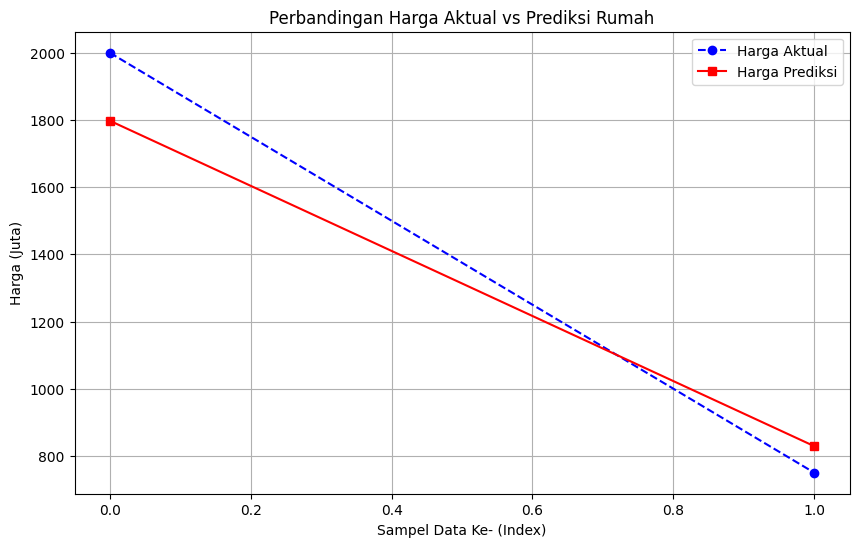

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

data_rumah = {
    'Luas_Tanah': [100, 150, np.nan, 200, 120, 300, 180, 90, 250, 110],
    'Jml_Kamar':  [2, 3, 3, 4, 2, 5, 3, 2, 4, np.nan],
    'Kondisi':    ['Baru', 'Lama', 'Baru', 'Baru', 'Lama', 'Baru', 'Lama', 'Lama', 'Baru', 'Lama'],
    'Harga_Juta': [500, 750, 800, 1000, 600, 2500, 850, 450, 2000, 550]
}
df_rumah = pd.DataFrame(data_rumah)

X = df_rumah.drop('Harga_Juta', axis=1)
y = df_rumah['Harga_Juta']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_numerik = Pipeline(steps=[
    ('isi_kosong_num', SimpleImputer(strategy='median')),
    ('skala_num', StandardScaler())
])

pipeline_kategori = Pipeline(steps=[
    ('isi_kosong_cat', SimpleImputer(strategy='most_frequent')),
    ('encode_cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_utama = ColumnTransformer(transformers=[
    ('proses_numerik', pipeline_numerik, ['Luas_Tanah', 'Jml_Kamar']),
    ('proses_kategori', pipeline_kategori, ['Kondisi'])
])

master_pipeline = Pipeline(steps=[
    ('semua_preprocessing', preprocessor_utama),
    ('algoritma_regresi', LinearRegression())
])

model_akhir = TransformedTargetRegressor(
    regressor=master_pipeline,
    transformer=StandardScaler()
)

model_akhir.fit(X_train, y_train)

prediksi_harga = model_akhir.predict(X_test)

print("\n=== Hasil Studi Kasus ===")
print("Aktual :", y_test.values)
print("Prediksi:", np.round(prediksi_harga, 2))
print("MAE    : Rp", np.round(mean_absolute_error(y_test, prediksi_harga), 2), "Juta")
print("R2     :", np.round(r2_score(y_test, prediksi_harga), 2))

# Visualisasi Plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_test)), y_test.values, marker='o', label='Harga Aktual', color='blue', linestyle='--')
plt.plot(range(len(y_test)), prediksi_harga, marker='s', label='Harga Prediksi', color='red', linestyle='-')
plt.title('Perbandingan Harga Aktual vs Prediksi Rumah')
plt.xlabel('Sampel Data Ke- (Index)')
plt.ylabel('Harga (Juta)')
plt.legend()
plt.grid(True)
plt.show()

Studi Kasus Logistic regression


=== Hasil Studi Kasus Logistic Regression ===
Aktual   : [0 0 1 1 1 1]
Prediksi : [0 0 1 0 1 1]
Akurasi  : 0.83

Classification Report:
               precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      0.75      0.86         4

    accuracy                           0.83         6
   macro avg       0.83      0.88      0.83         6
weighted avg       0.89      0.83      0.84         6



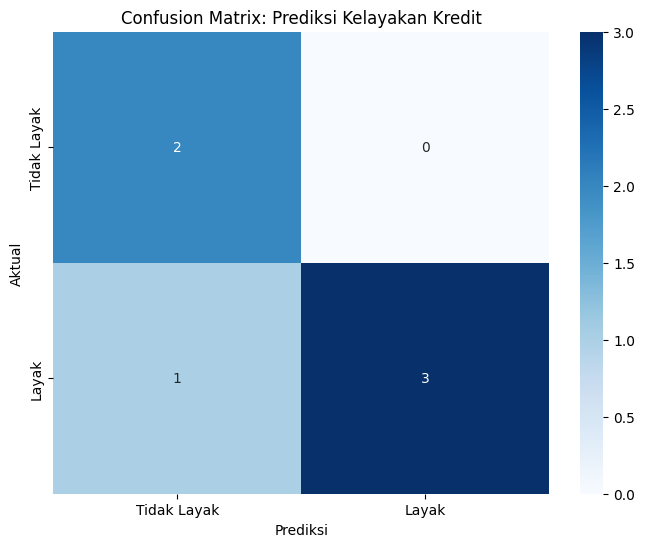

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

data_kredit = {
    'Pendapatan': [5, 10, np.nan, 15, 7, 25, 12, 4, 20, 8, 3, 22, 6, 18, 9, 28, 11, 5, 24, 7],
    'Usia':       [25, 30, 35, 45, 28, 50, 40, 22, 48, np.nan, 21, 55, 26, 42, 33, 58, 38, 24, 52, 29],
    'Status_Kerja': ['Tetap', 'Kontrak', 'Tetap', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Kontrak', 'Tetap', 'Kontrak',
                    'Kontrak', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Kontrak', 'Tetap', 'Kontrak'],
    'Layak_Kredit': [0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0]
}
df_kredit = pd.DataFrame(data_kredit)

X = df_kredit.drop('Layak_Kredit', axis=1)
y = df_kredit['Layak_Kredit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

pipeline_numerik = Pipeline(steps=[
    ('isi_kosong_num', SimpleImputer(strategy='mean')),
    ('skala_num', StandardScaler())
])

pipeline_kategori = Pipeline(steps=[
    ('isi_kosong_cat', SimpleImputer(strategy='most_frequent')),
    ('encode_cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_utama = ColumnTransformer(transformers=[
    ('proses_numerik', pipeline_numerik, ['Pendapatan', 'Usia']),
    ('proses_kategori', pipeline_kategori, ['Status_Kerja'])
])

model_akhir = Pipeline(steps=[
    ('semua_preprocessing', preprocessor_utama),
    ('algoritma_klasifikasi', LogisticRegression())
])

model_akhir.fit(X_train, y_train)

prediksi_layak = model_akhir.predict(X_test)

print("\n=== Hasil Studi Kasus Logistic Regression ===")
print("Aktual   :", y_test.values)
print("Prediksi :", prediksi_layak)
print("Akurasi  :", np.round(accuracy_score(y_test, prediksi_layak), 2))
print("\nClassification Report:\n", classification_report(y_test, prediksi_layak))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, prediksi_layak)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Tidak Layak', 'Layak'], 
            yticklabels=['Tidak Layak', 'Layak'])
plt.title('Confusion Matrix: Prediksi Kelayakan Kredit')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()